In [2]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import requests
import io
# URL of the CSV file
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

# Fetch the data from the URL
response = requests.get(URL)

# Raise an error if the request failed
response.raise_for_status()

# Convert the response content into a readable format for pandas
csv_content = io.StringIO(response.text)

# Read the CSV data into a pandas dataframe
df = pd.read_csv(csv_content)

# Print confirmation
print('Data downloaded and read into a dataframe!')

# Optional: Show the first few rows of the dataframe
print(df.head())

Data downloaded and read into a dataframe!
         Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0  1980-01-31  1980   Jan          1               108.24                0.45   
1  1980-01-31  1980   Jan          1               108.24                0.45   
2  1980-01-31  1980   Jan          1               108.24                0.36   
3  1980-01-31  1980   Jan          1               108.24                0.38   
4  1980-02-29  1980   Feb          1                98.75                0.46   

   Price  Advertising_Expenditure  Competition    GDP  Growth_Rate  \
0  27704                   1417.5            7  60.22         0.01   
1  77270                    763.7            7  60.22         0.01   
2  19665                   1417.5            7  60.22         0.01   
3  36986                   1417.5            7  60.22         0.01   
4  26609                   2773.4            4  45.99        -0.31   

   unemployment_rate  Automobile_Sales     Vehicl

In [6]:
df.columns

Index(['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence',
       'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition',
       'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales',
       'Vehicle_Type', 'City'],
      dtype='object')

In [3]:
import pandas as pd

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

df = pd.read_csv(URL)

print("Data downloaded and read into a dataframe!")
df.head()

Data downloaded and read into a dataframe!


,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1980-01-31,1980,Jan,1,108.24,0.45,27704,1417.5,7,60.22,0.01,5.4,220.0,SmallFamilyCar,Georgia
1,1980-01-31,1980,Jan,1,108.24,0.45,77270,763.7,7,60.22,0.01,5.4,72.0,Sports,Georgia
2,1980-01-31,1980,Jan,1,108.24,0.36,19665,1417.5,7,60.22,0.01,5.4,238.0,SuperMiniCar,Georgia
3,1980-01-31,1980,Jan,1,108.24,0.38,36986,1417.5,7,60.22,0.01,5.4,224.0,MediumFamilyCar,Georgia
4,1980-02-29,1980,Feb,1,98.75,0.46,26609,2773.4,4,45.99,-0.31,4.8,280.0,SmallFamilyCar,New York


In [5]:
df.shape

(2112, 15)

<Figure size 1200x700 with 0 Axes>

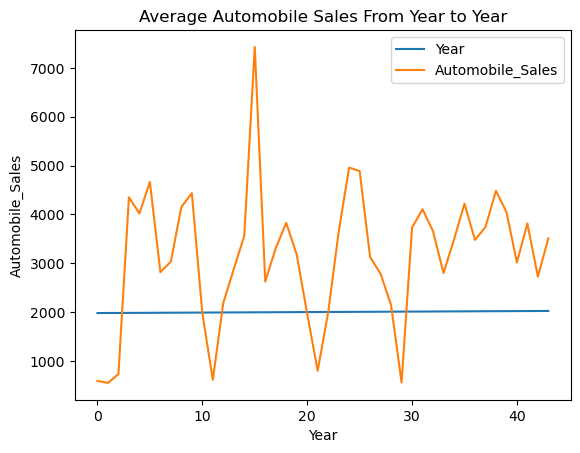

In [9]:
plt.figure(figsize = (12, 7))

line_chart = df.groupby('Year')['Automobile_Sales'].mean().reset_index()

line_chart.plot(kind = 'line')
plt.xlabel('Year')
plt.ylabel('Automobile_Sales')
plt.title('Average Automobile Sales From Year to Year')
plt.show()

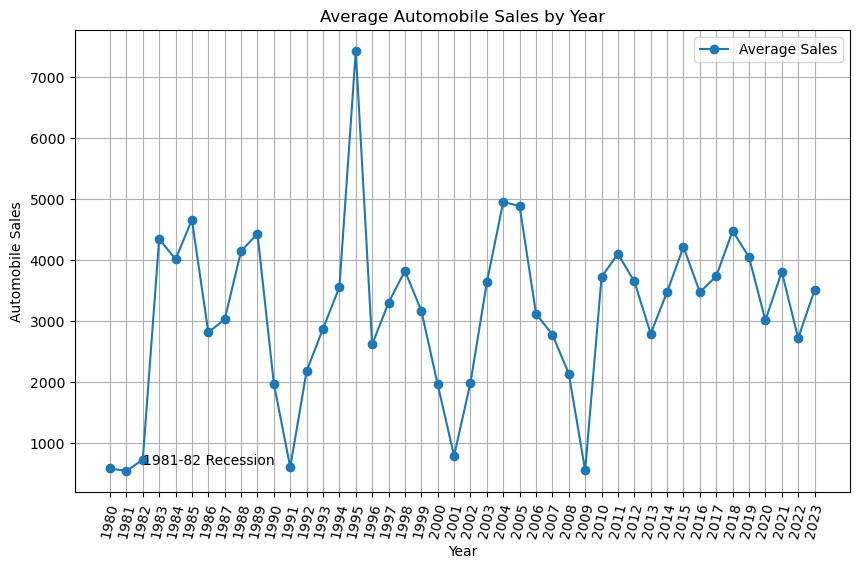

In [25]:
plt.figure(figsize=(10,6))

line_chart = df.groupby('Year')['Automobile_Sales'].mean().reset_index()

plt.plot(
    line_chart['Year'],
    line_chart['Automobile_Sales'],
    marker='o',
    label='Average Sales'
)
plt.xticks(range(1980,2024), rotation=77)
plt.xlabel('Year')
plt.ylabel('Automobile Sales')
plt.title('Average Automobile Sales by Year')

plt.text(1982, 650, '1981-82 Recession')

plt.legend()
plt.grid(True)

plt.show()


/var/folders/vm/gd8s19s96yl_jh_39hpshvnc0000gn/T/ipykernel_14609/464706467.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


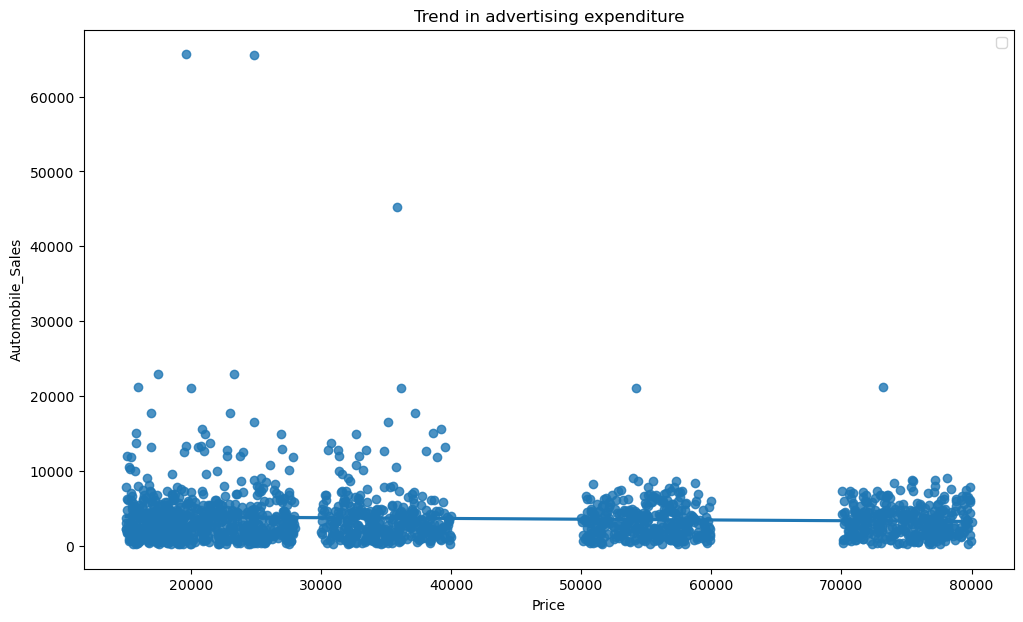

In [6]:
import matplotlib.pyplot as plt 
import seaborn as sns
import pandas as pd

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

df = pd.read_csv(URL)

plt.figure(figsize = (12, 7))

df_Vis = df[df['Recession'] == 0]

sns.regplot(
    x = 'Price',
    y = 'Automobile_Sales',
    data = df_Vis
)
plt.title('Trend in advertising expenditure')
plt.legend()
plt.show()


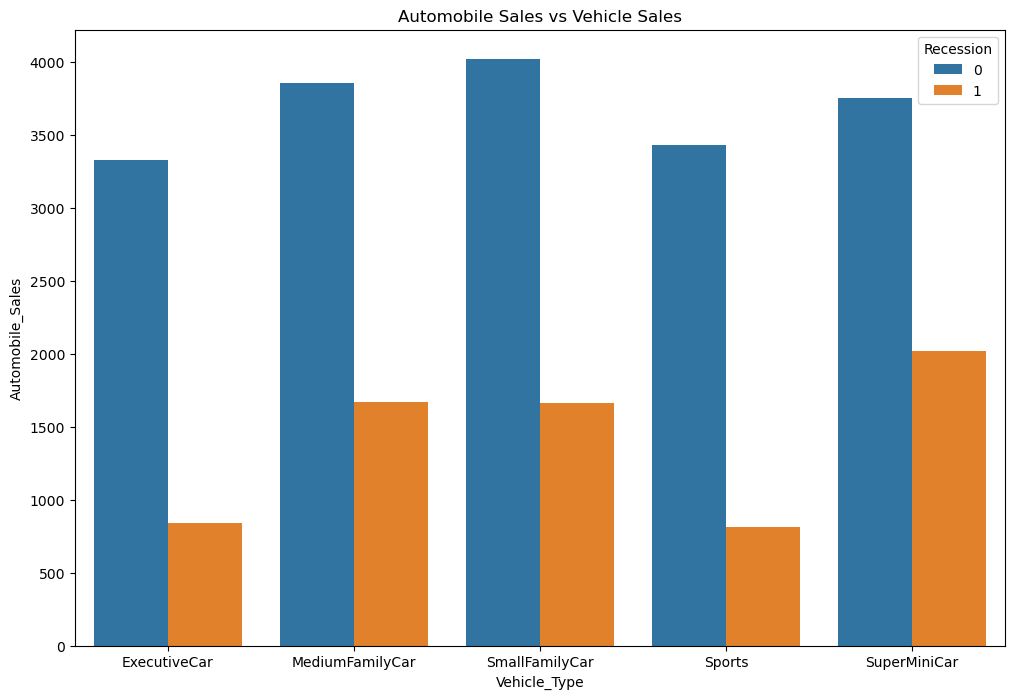

In [44]:
plt.figure(figsize = ( 12, 8))

sales_types = df.groupby(['Recession', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()

sns.barplot(
    x = 'Vehicle_Type',
    y = 'Automobile_Sales',
    hue = 'Recession',
    data= sales_types
)
plt.xlabel('Vehicle_Type')
plt.ylabel('Automobile_Sales')
plt.title('Automobile Sales vs Vehicle Sales')
plt.show()

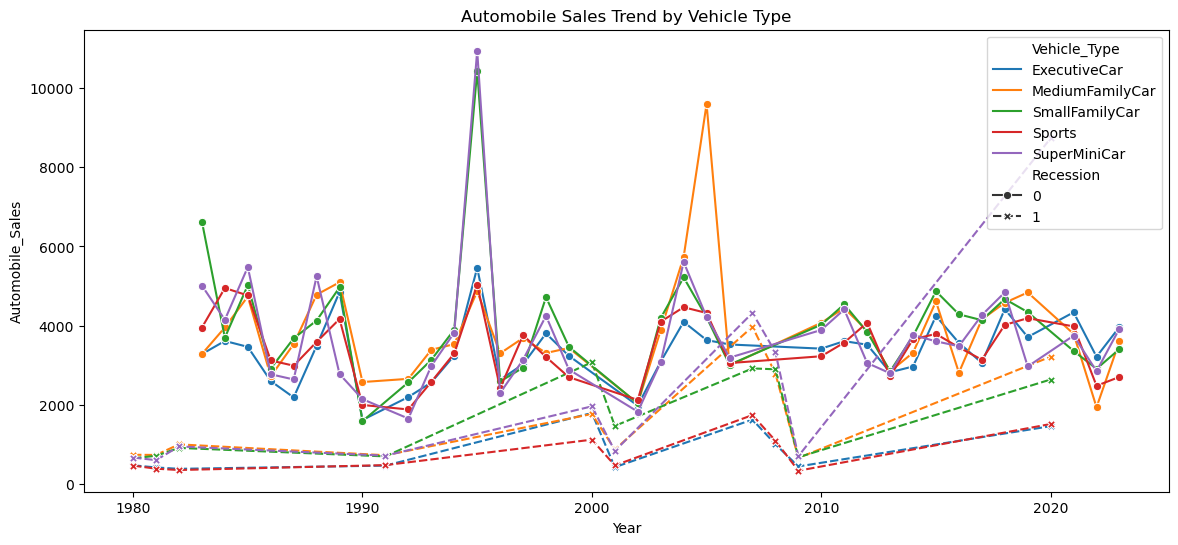

In [45]:
sales_trend = df.groupby(
    ['Year', 'Recession', 'Vehicle_Type']
)['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(14,6))

sns.lineplot(
    data=sales_trend,
    x='Year',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    style='Recession',
    markers=True
)

plt.title('Automobile Sales Trend by Vehicle Type')
plt.show()

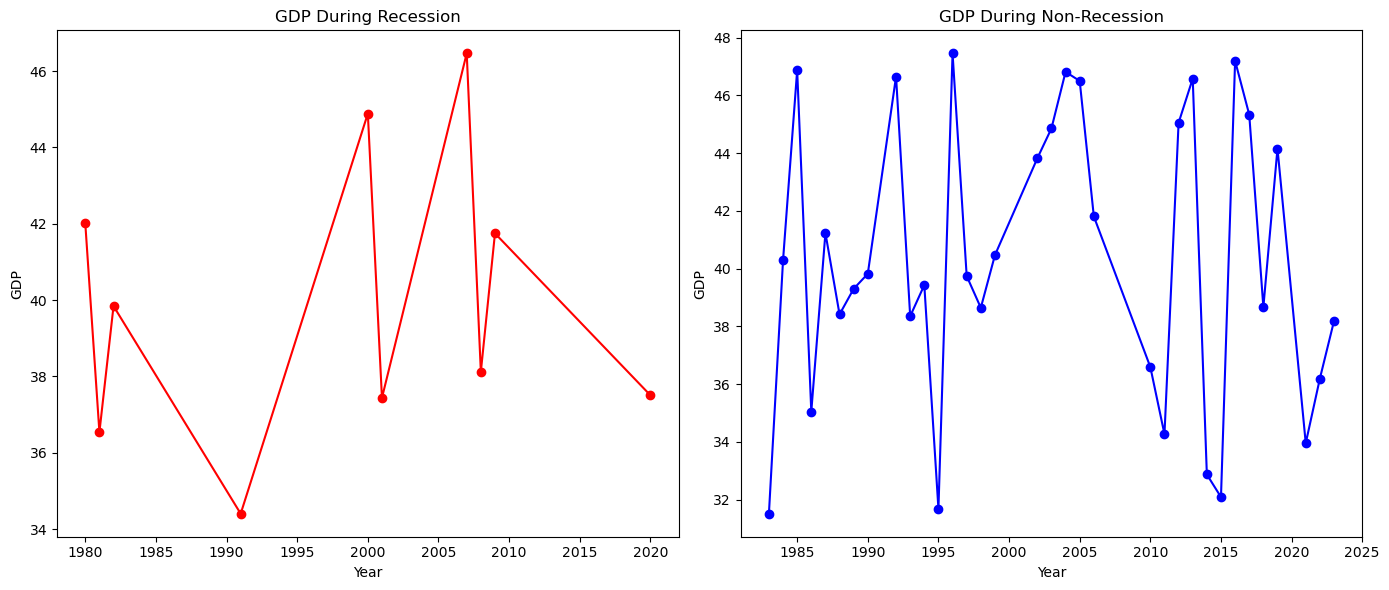

In [62]:
import matplotlib.pyplot as plt

# Filter data
recession = df[df['Recession'] == 1]
non_recession = df[df['Recession'] == 0]

# Calculate average GDP by year
rec_gdp = recession.groupby('Year')['GDP'].mean().reset_index()
non_rec_gdp = non_recession.groupby('Year')['GDP'].mean().reset_index()

# Create subplots
fig, ax = plt.subplots(1, 2, figsize=(14,6))

# Recession plot
ax[0].plot(
    rec_gdp['Year'],
    rec_gdp['GDP'],
    marker='o',
    color='red'
)

ax[0].set_title('GDP During Recession')
ax[0].set_xlabel('Year')
ax[0].set_ylabel('GDP')

# Non-Recession plot
ax[1].plot(
    non_rec_gdp['Year'],
    non_rec_gdp['GDP'],
    marker='o',
    color='blue'
)

ax[1].set_title('GDP During Non-Recession')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('GDP')

plt.tight_layout()

plt.show()

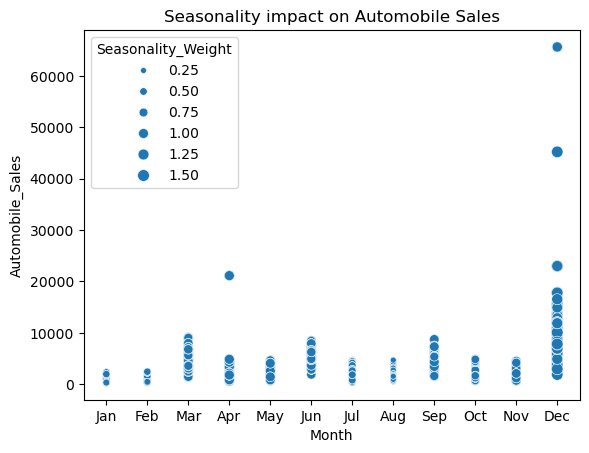

In [80]:
non_rec_data = df[df['Recession'] == 0]
    
size=non_rec_data['Seasonality_Weight'] #for bubble effect
    
sns.scatterplot(
    data=non_rec_data, 
    x='Month',
    y='Automobile_Sales',
    size= 'Seasonality_Weight'
)
    
    #you can further include hue='Seasonality_Weight', legend=False)

plt.xlabel('Month')
plt.ylabel('Automobile_Sales')
plt.legend = False
plt.title('Seasonality impact on Automobile Sales')

plt.show()

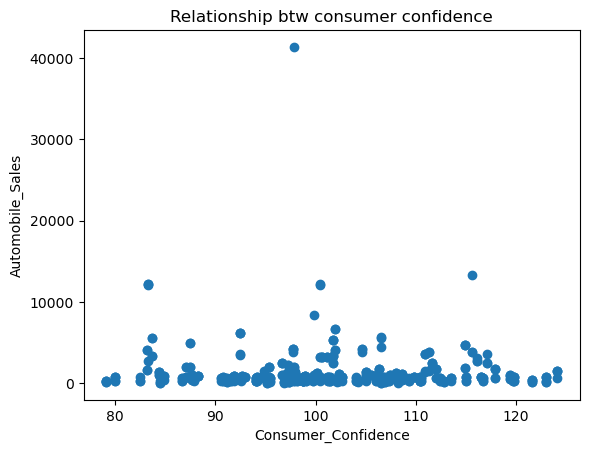

In [86]:
Recession1 = df[df['Recession'] == 1]

plt.scatter(
    x = 'Consumer_Confidence',
    y = 'Automobile_Sales',
    data = Recession1
)
plt.title('Relationship btw consumer confidence')
plt.xlabel('Consumer_Confidence')
plt.ylabel('Automobile_Sales')
plt.legend = True
plt.show()

Recession
0    5031103.0
1    1050915.6
Name: Advertising_Expenditure, dtype: float64


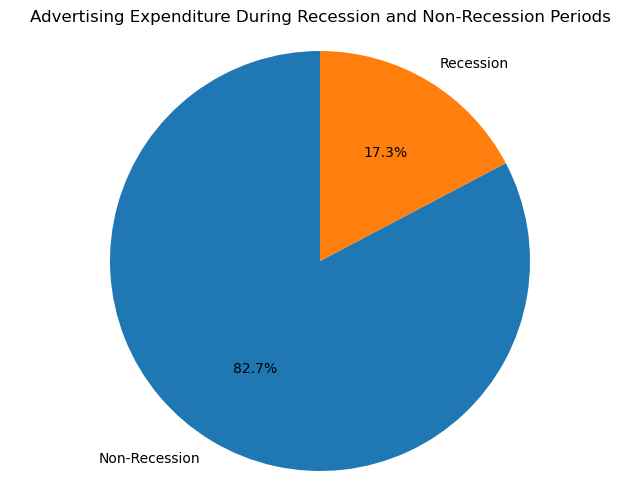

In [89]:
import matplotlib.pyplot as plt

ad_exp = df.groupby('Recession')['Advertising_Expenditure'].sum()

print(ad_exp)

plt.figure(figsize=(8, 6))

plt.pie(
    ad_exp,
    labels=['Non-Recession', 'Recession'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Advertising Expenditure During Recession and Non-Recession Periods')
plt.axis('equal')

plt.show()

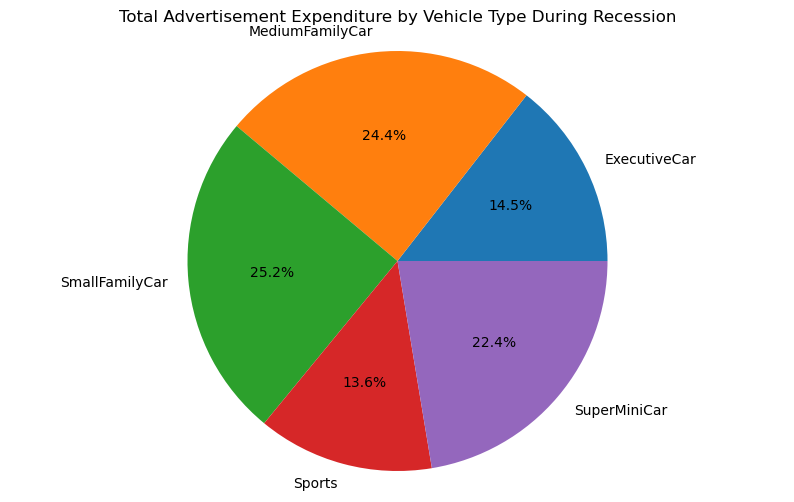

In [94]:
recession_data = df[df['Recession'] == 1]

ad_exp_vehicle = recession_data.groupby(
    'Vehicle_Type'
)['Advertising_Expenditure'].sum()

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.pie(
    ad_exp_vehicle,
    labels=ad_exp_vehicle.index,
    autopct='%1.1f%%'
)

plt.title('Total Advertisement Expenditure by Vehicle Type During Recession')
plt.axis('equal')

plt.show()

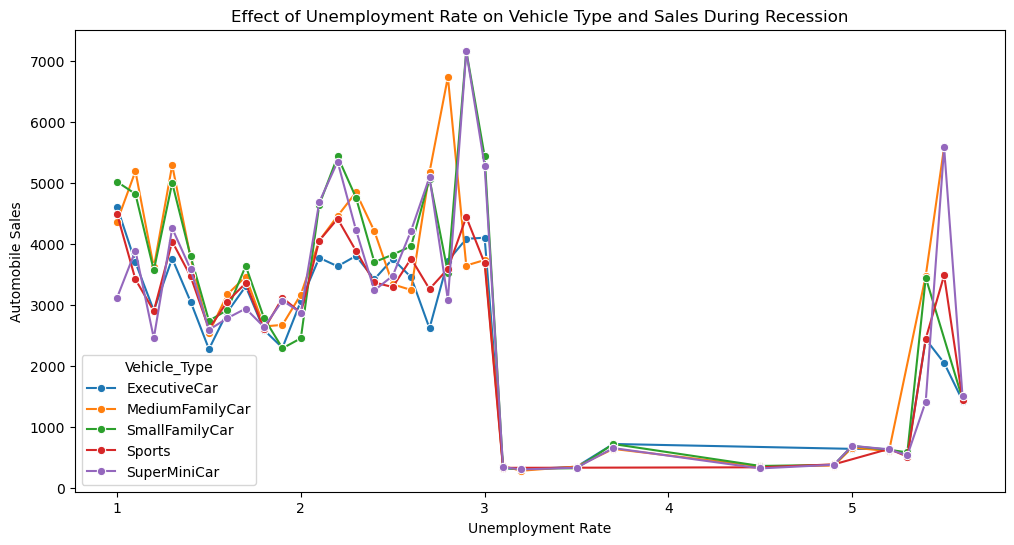

In [115]:
recession_data = df[df['Recession'] == 0]

import matplotlib.pyplot as plt
import seaborn as sns

recession_sales = recession_data.groupby(
    ['unemployment_rate', 'Vehicle_Type']
)['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=recession_sales,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

plt.title('Effect of Unemployment Rate on Vehicle Type and Sales During Recession')
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')

plt.show()

In [113]:
df.columns

Index(['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence',
       'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition',
       'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales',
       'Vehicle_Type', 'City'],
      dtype='object')

In [ ]:
recession_data = df[df['Recession'] == 1]

sales_by_state = (
    recession_data
    .groupby('State')['Automobile_Sales']
    .sum()
    .reset_index()
)

map1 = folium.Map(
    location=[37.0902, -95.7129],
    zoom_start=4
)

choropleth = folium.Choropleth(
    geo_data='us-states.json',
    data=sales_by_state,
    columns=['State', 'Automobile_Sales'],
    key_on='feature.properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name='Automobile Sales during Recession'
).add_to(map1)

choropleth.geojson.add_child(
    folium.features.GeoJsonTooltip(
        ['name'],
        labels=True
    )
)

map1

In [1]:
# Import required libraries
import pandas as pd
import dash
from dash import dcc
from dash import html
from dash.dependencies import Input, Output
import plotly.express as px

# Read the airline data into pandas dataframe
airline_data =  pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/airline_data.csv', 
                            encoding = "ISO-8859-1",
                            dtype={'Div1Airport': str, 'Div1TailNum': str, 
                                   'Div2Airport': str, 'Div2TailNum': str})

# Create a dash application
app = dash.Dash(__name__)

# Build dash app layout
app.layout = html.Div(children=[ html.H1('Flight Delay Time Statistics', 
                                style={'textAlign': 'center', 'color': '#503D36',
                                'font-size': 30}),
                                html.Div(["Input Year: ", dcc.Input(id='input-year', value='2010', 
                                type='number', style={'height':'35px', 'font-size': 30}),], 
                                style={'font-size': 30}),
                                html.Br(),
                                html.Br(), 
                                # Segment 1
                                html.Div([
                                        html.Div(dcc.Graph(id='carrier-plot')),
                                        html.Div(dcc.Graph(id='weather-plot'))
                                ], style={'display': 'flex'}),
                                # Segment 2
                                html.Div([
                                        html.Div(dcc.Graph(id='nas-plot')),
                                        html.Div(dcc.Graph(id='security-plot'))
                                ], style={'display': 'flex'}),
                                # Segment 3
                                html.Div(dcc.Graph(id='late-plot'), style={'width':'65%'})
                                ])

""" Compute_info function description

This function takes in airline data and selected year as an input and performs computation for creating charts and plots.

Arguments:
    airline_data: Input airline data.
    entered_year: Input year for which computation needs to be performed.
    
Returns:
    Computed average dataframes for carrier delay, weather delay, NAS delay, security delay, and late aircraft delay.

"""
def compute_info(airline_data, entered_year):
    # Select data
    df =  airline_data[airline_data['Year']==int(entered_year)]
    # Compute delay averages
    avg_car = df.groupby(['Month','Reporting_Airline'])['CarrierDelay'].mean().reset_index()
    avg_weather = df.groupby(['Month','Reporting_Airline'])['WeatherDelay'].mean().reset_index()
    avg_NAS = df.groupby(['Month','Reporting_Airline'])['NASDelay'].mean().reset_index()
    avg_sec = df.groupby(['Month','Reporting_Airline'])['SecurityDelay'].mean().reset_index()
    avg_late = df.groupby(['Month','Reporting_Airline'])['LateAircraftDelay'].mean().reset_index()
    return avg_car, avg_weather, avg_NAS, avg_sec, avg_late

"""Callback Function

Function that returns fugures using the provided input year.

Arguments:

    entered_year: Input year provided by the user.
    
Returns:

    List of figures computed using the provided helper function `compute_info`.
"""
# Callback decorator
@app.callback( [
               Output(component_id='carrier-plot', component_property='figure'),
               Output(component_id='weather-plot', component_property='figure'),
               Output(component_id='nas-plot', component_property='figure'),
               Output(component_id='security-plot', component_property='figure'),
               Output(component_id='late-plot', component_property='figure')
               ],
               Input(component_id='input-year', component_property='value'))
# Computation to callback function and return graph
def get_graph(entered_year):
    
    # Compute required information for creating graph from the data
    avg_car, avg_weather, avg_NAS, avg_sec, avg_late = compute_info(airline_data, entered_year)
            
    # Line plot for carrier delay
    carrier_fig = px.line(avg_car, x='Month', y='CarrierDelay', color='Reporting_Airline', title='Average carrrier delay time (minutes) by airline')
    # Line plot for weather delay
    weather_fig = px.line(avg_weather, x='Month', y='WeatherDelay', color='Reporting_Airline', title='Average weather delay time (minutes) by airline')
    # Line plot for nas delay
    nas_fig = px.line(avg_NAS, x='Month', y='NASDelay', color='Reporting_Airline', title='Average NAS delay time (minutes) by airline')
    # Line plot for security delay
    sec_fig = px.line(avg_sec, x='Month', y='SecurityDelay', color='Reporting_Airline', title='Average security delay time (minutes) by airline')
    # Line plot for late aircraft delay
    late_fig = px.line(avg_late, x='Month', y='LateAircraftDelay', color='Reporting_Airline', title='Average late aircraft delay time (minutes) by airline')
            
    return[carrier_fig, weather_fig, nas_fig, sec_fig, late_fig]

# Run the app
if __name__ == '__main__':
    app.run()


In [8]:
import pandas as pd

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

df = pd.read_csv(URL)

df.head()

,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1980-01-31,1980,Jan,1,108.24,0.45,27704,1417.5,7,60.22,0.01,5.4,220.0,SmallFamilyCar,Georgia
1,1980-01-31,1980,Jan,1,108.24,0.45,77270,763.7,7,60.22,0.01,5.4,72.0,Sports,Georgia
2,1980-01-31,1980,Jan,1,108.24,0.36,19665,1417.5,7,60.22,0.01,5.4,238.0,SuperMiniCar,Georgia
3,1980-01-31,1980,Jan,1,108.24,0.38,36986,1417.5,7,60.22,0.01,5.4,224.0,MediumFamilyCar,Georgia
4,1980-02-29,1980,Feb,1,98.75,0.46,26609,2773.4,4,45.99,-0.31,4.8,280.0,SmallFamilyCar,New York


In [6]:
%whos

Variable               Type         Data/Info
---------------------------------------------
Input                  type         <class 'dash.dependencies.Input'>
Output                 type         <class 'dash.dependencies.Output'>
airline_data           DataFrame    Shape: (27000, 110)
app                    Dash         <dash.dash.Dash object at 0x12d300590>
compute_info           function     <function compute_info at 0x12fe9fce0>
dash                   module       <module 'dash' from '/opt<...>ckages/dash/__init__.py'>
dataframe_columns      function     <function dataframe_columns at 0x13c80e8e0>
dataframe_hash         function     <function dataframe_hash at 0x13bfce480>
dcc                    module       <module 'dash.dcc' from '<...>es/dash/dcc/__init__.py'>
dtypes_str             function     <function dtypes_str at 0x13bfce840>
get_dataframes         function     <function get_dataframes at 0x13bfcf4c0>
get_graph              function     <function get_graph at 0x12fec00e0

In [11]:
print(df.columns.tolist())

['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence', 'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition', 'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales', 'Vehicle_Type', 'City']


In [12]:
print(df['City'].unique())

['Georgia' 'New York' 'Illinois' 'California']


In [13]:
print(df[['City', 'Automobile_Sales', 'Recession']].head())

       City  Automobile_Sales  Recession
0   Georgia             220.0          1
1   Georgia              72.0          1
2   Georgia             238.0          1
3   Georgia             224.0          1
4  New York             280.0          1
